# Autoencoder 1D para reconstrução da curva Gamma Ray

Parte 2 do projeto: leitura da curva Gamma Ray (DLIS/CSV), pré-processamento, janelamento, treino de um Autoencoder Conv1D e comparação com baselines (PCA, média móvel, Isolation Forest).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import matplotlib.pyplot as plt

from signals.gamma_ray_loader import load_gamma_ray, GAMMA_RAY_MNEMONICS
from signals.preprocessing import preprocess_curve
from signals.windowing import make_windows, train_test_split_windows
from signals.autoencoder import Conv1DAutoencoder, train_autoencoder, reconstruct, reconstruction_error
from evaluation.reconstruction_metrics import (
    score_reconstruction, pca_baseline, moving_average_baseline,
    isolation_forest_scores, extract_window_features,
)
from visualization.plot_gamma_ray import (
    plot_curve, plot_original_vs_reconstructed, plot_reconstruction_error,
    plot_error_distribution, plot_method_comparison,
)

np.random.seed(42)

## 1. Carregamento da curva Gamma Ray

Procura automaticamente um arquivo `.dlis` ou `.csv` em `data/raw/gamma_ray/`. Se nenhum arquivo real for encontrado, gera uma curva sintética (com anomalias injetadas) apenas para validar o pipeline.

In [2]:
GAMMA_RAY_DIR = PROJECT_ROOT / "data" / "raw" / "gamma_ray"

# Dataset ANP: arquivos .dlis ficam em subpastas <well_id>/dlis/*.dlis;
# manifest.csv é apenas um índice (well_id, tipo, caminho), não é uma curva.
candidates = sorted(GAMMA_RAY_DIR.rglob("*.dlis")) + sorted(
    p for p in GAMMA_RAY_DIR.glob("*.csv") if p.name != "manifest.csv"
)

USE_SYNTHETIC = len(candidates) == 0

if not USE_SYNTHETIC:
    source_path = candidates[0]
    print(f"Arquivo encontrado: {source_path.relative_to(GAMMA_RAY_DIR)}")
    curve = load_gamma_ray(source_path)
    depth_raw, gr_raw = curve.depth, curve.gamma_ray
    well_name = curve.well_name
    print(f"Poço: {well_name} | {len(depth_raw)} pontos | profundidade {depth_raw.min():.1f}-{depth_raw.max():.1f}")
else:
    print(f"Nenhum arquivo .dlis/.csv encontrado em {GAMMA_RAY_DIR}.")
    print("Gerando curva Gamma Ray SINTÉTICA apenas para validar o pipeline.")
    rng = np.random.default_rng(42)
    depth_raw = np.arange(1000, 1800, 0.15)
    trend = 60 + 25 * np.sin(depth_raw / 25) + 10 * np.sin(depth_raw / 4)
    noise = rng.normal(0, 4, size=depth_raw.shape)
    gr_raw = trend + noise

    anomaly_zones = [(1150, 1160), (1420, 1435), (1690, 1700)]
    for lo, hi in anomaly_zones:
        mask = (depth_raw >= lo) & (depth_raw <= hi)
        gr_raw[mask] += rng.normal(45, 5, size=mask.sum())

    well_name = "SYNTHETIC-WELL-01"
    print(f"Poço sintético: {well_name} | {len(depth_raw)} pontos | profundidade {depth_raw.min():.1f}-{depth_raw.max():.1f}")

Arquivo encontrado: 1-WINT-2-RJS\dlis\1-wint-2-rjs_cmr_079pup.dlis


Poço: 1-WINT-2-RJS | 17535 pontos | profundidade 2821.9-3712.6


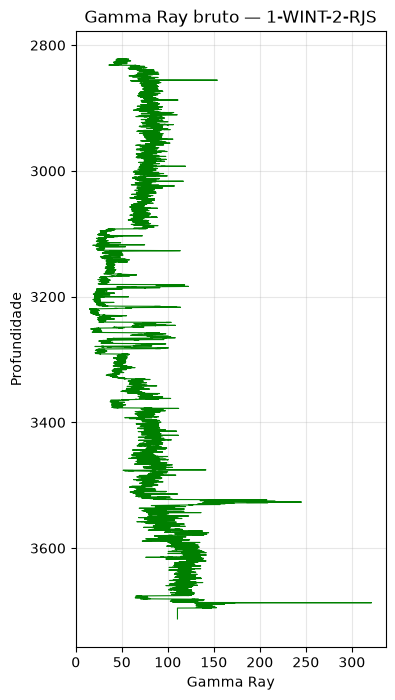

In [3]:
fig, ax = plt.subplots(figsize=(4, 8))
plot_curve(depth_raw, gr_raw, title=f"Gamma Ray bruto — {well_name}", ax=ax)
plt.show()

## 2. Pré-processamento

Ordenação por profundidade, remoção de duplicatas, interpolação de valores ausentes/inválidos (ex.: `-999.25`), clipping de outliers extremos e normalização (z-score).

Após pré-processamento: 17535 pontos
Normalização -> mean=75.289, std=29.385


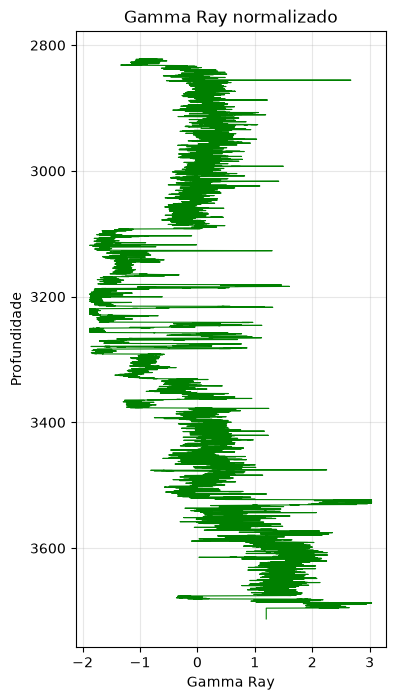

In [4]:
depth, gr_norm, norm_params = preprocess_curve(depth_raw, gr_raw, clip_pct=(0.5, 99.5))

print(f"Após pré-processamento: {len(depth)} pontos")
print(f"Normalização -> mean={norm_params.mean:.3f}, std={norm_params.std:.3f}")

fig, ax = plt.subplots(figsize=(4, 8))
plot_curve(depth, gr_norm, title="Gamma Ray normalizado", ax=ax)
plt.show()

## 3. Janelamento e split treino/teste

Divide a curva em janelas de tamanho fixo (múltiplo de 4, exigido pela arquitetura Conv1D do Autoencoder) e separa treino/teste.

Duas visões são mantidas:
- `train`/`test` embaralhados — usados para treinar e comparar métricas agregadas (MSE/MAE);
- `windows_ordered` (sem shuffle, cobrindo toda a curva em profundidade) — usada para plotar o erro de reconstrução ao longo da profundidade.

In [5]:
WINDOW_SIZE = 64  # múltiplo de 4; ajuste para 128/256 se a curva for longa o suficiente
STRIDE = 32        # 50% de sobreposição para treino/teste (mais amostras)

windows = make_windows(depth, gr_norm, window_size=WINDOW_SIZE, stride=STRIDE)
train, test = train_test_split_windows(windows, test_size=0.2, shuffle=True, seed=42)

# janelas sem sobreposição e sem shuffle, cobrindo toda a curva -> para o gráfico de erro x profundidade
windows_ordered = make_windows(depth, gr_norm, window_size=WINDOW_SIZE, stride=WINDOW_SIZE)

print(f"Total de janelas (treino/teste): {windows.data.shape}")
print(f"Treino: {train.data.shape} | Teste: {test.data.shape}")
print(f"Janelas ordenadas (para análise por profundidade): {windows_ordered.data.shape}")

Total de janelas (treino/teste): (546, 64)
Treino: (437, 64) | Teste: (109, 64)
Janelas ordenadas (para análise por profundidade): (273, 64)


## 4. Treino do Autoencoder Conv1D

In [6]:
model = Conv1DAutoencoder(window_size=WINDOW_SIZE, latent_channels=16)

history = train_autoencoder(
    model,
    train_windows=train.data,
    val_windows=test.data,
    epochs=100,
    batch_size=32,
    lr=1e-3,
    verbose=True,
)

[epoch 001/100] train_loss=0.94358 | val_loss=0.95208
[epoch 005/100] train_loss=0.07038 | val_loss=0.07286


[epoch 010/100] train_loss=0.02199 | val_loss=0.02043


[epoch 015/100] train_loss=0.00977 | val_loss=0.00977


[epoch 020/100] train_loss=0.00775 | val_loss=0.00887


[epoch 025/100] train_loss=0.00644 | val_loss=0.00654


...

[epoch 080/100] train_loss=0.00197 | val_loss=0.00218


[epoch 085/100] train_loss=0.00196 | val_loss=0.00218


[epoch 090/100] train_loss=0.00198 | val_loss=0.00245


[epoch 095/100] train_loss=0.00182 | val_loss=0.00205


[epoch 100/100] train_loss=0.00174 | val_loss=0.00192


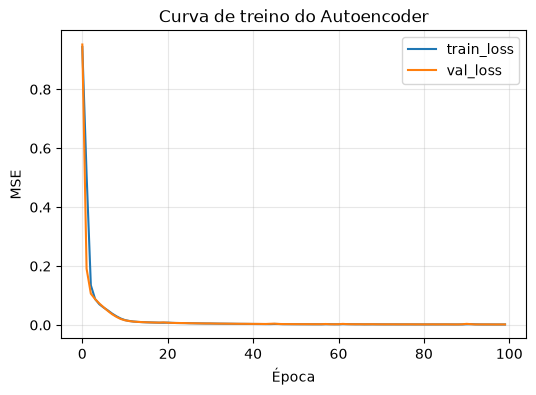

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history.train_loss, label="train_loss")
ax.plot(history.val_loss, label="val_loss")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.set_title("Curva de treino do Autoencoder")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Reconstrução e métricas no conjunto de teste (Autoencoder vs. baselines)

Baselines: PCA, média móvel (suavização) e Isolation Forest (score de anomalia sobre features estatísticas das janelas).

In [8]:
# --- Autoencoder ---
test_recon = reconstruct(model, test.data)
ae_scores = score_reconstruction(test.data, test_recon)

# --- Baseline 1: PCA ---
pca_recon = pca_baseline(train.data, test.data, n_components=8)
pca_scores = score_reconstruction(test.data, pca_recon)

# --- Baseline 2: média móvel ---
ma_recon = moving_average_baseline(test.data, window_length=9)
ma_scores = score_reconstruction(test.data, ma_recon)

print(f"{'Método':<20}{'MSE':>10}{'MAE':>10}")
print(f"{'Autoencoder Conv1D':<20}{ae_scores.mse:>10.4f}{ae_scores.mae:>10.4f}")
print(f"{'PCA (8 comp.)':<20}{pca_scores.mse:>10.4f}{pca_scores.mae:>10.4f}")
print(f"{'Média móvel':<20}{ma_scores.mse:>10.4f}{ma_scores.mae:>10.4f}")

Método                     MSE       MAE
Autoencoder Conv1D      0.0019    0.0325
PCA (8 comp.)           0.0138    0.0891
Média móvel             0.0112    0.0800


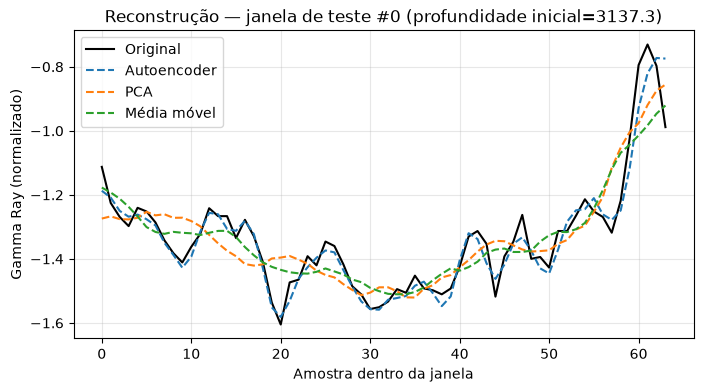

In [9]:
# Exemplo qualitativo: compara uma janela de teste específica (original x AE x PCA x média móvel)
idx = 0
window_depth = np.arange(WINDOW_SIZE)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(window_depth, test.data[idx], label="Original", color="black", linewidth=1.5)
ax.plot(window_depth, test_recon[idx], label="Autoencoder", linestyle="--")
ax.plot(window_depth, pca_recon[idx], label="PCA", linestyle="--")
ax.plot(window_depth, ma_recon[idx], label="Média móvel", linestyle="--")
ax.set_xlabel("Amostra dentro da janela")
ax.set_ylabel("Gamma Ray (normalizado)")
ax.set_title(f"Reconstrução — janela de teste #{idx} (profundidade inicial={test.start_depths[idx]:.1f})")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 6. Reconstrução da curva completa e erro por profundidade

Aqui usamos `windows_ordered` (janelas contíguas, sem sobreposição, cobrindo toda a curva) para reconstruir a curva inteira e visualizar o erro ao longo da profundidade — é essa visão que permite destacar os intervalos com comportamento incomum.

In [10]:
full_recon = reconstruct(model, windows_ordered.data)

# "achata" as janelas de volta em uma série contínua (não há sobreposição, então é uma concatenação direta)
full_depth = np.concatenate([
    depth[np.searchsorted(depth, s): np.searchsorted(depth, s) + WINDOW_SIZE]
    for s in windows_ordered.start_depths
])
full_original_flat = windows_ordered.data.reshape(-1)
full_recon_flat = full_recon.reshape(-1)

per_window_error = reconstruction_error(windows_ordered.data, full_recon)
# erro "espalhado" por amostra (repete o erro da janela para cada um dos seus pontos) -> alinhado com full_depth
per_sample_error = np.repeat(per_window_error, WINDOW_SIZE)

print(f"Curva reconstruída: {len(full_depth)} pontos em {len(per_window_error)} janelas")

Curva reconstruída: 17472 pontos em 273 janelas


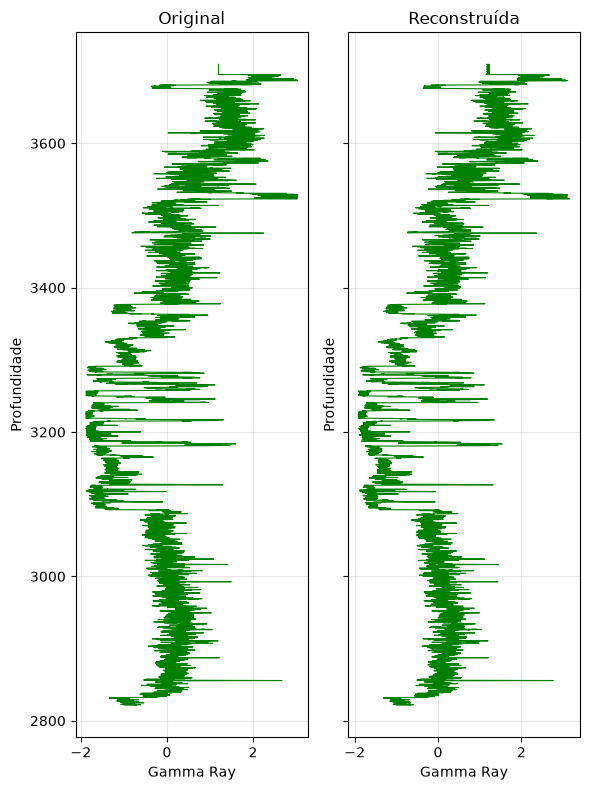

In [11]:
plot_original_vs_reconstructed(full_depth, full_original_flat, full_recon_flat)
plt.show()

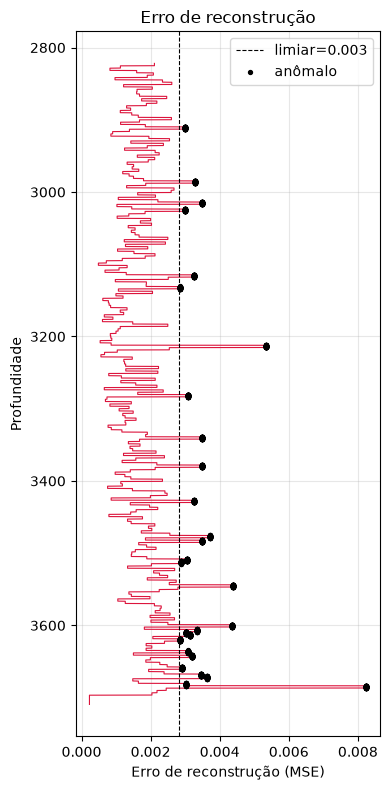

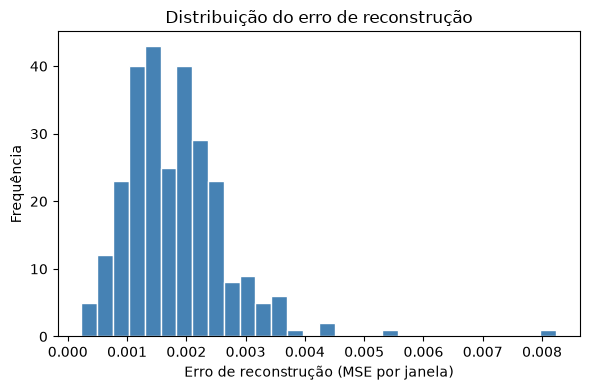

In [12]:
# Limiar de anomalia: percentil 90 do erro por janela (ajustável)
threshold = np.percentile(per_window_error, 90)

plot_reconstruction_error(full_depth, per_sample_error, threshold=threshold)
plt.show()

plot_error_distribution(per_window_error)
plt.show()

In [13]:
# Lista dos intervalos de profundidade com maior erro de reconstrução (top-N janelas)
top_n = 5
top_idx = np.argsort(per_window_error)[::-1][:top_n]

print("Janelas com maior erro de reconstrução:")
for rank, i in enumerate(sorted(top_idx, key=lambda i: windows_ordered.start_depths[i]), start=1):
    start = windows_ordered.start_depths[i]
    end = start + WINDOW_SIZE * np.median(np.diff(depth))
    print(f"  {rank}. profundidade ~{start:.1f} a ~{end:.1f} | erro={per_window_error[i]:.4f}")

Janelas com maior erro de reconstrução:
  1. profundidade ~3212.0 a ~3215.3 | erro=0.0053
  2. profundidade ~3475.4 a ~3478.6 | erro=0.0037
  3. profundidade ~3543.7 a ~3546.9 | erro=0.0044
  4. profundidade ~3598.9 a ~3602.2 | erro=0.0044
  5. profundidade ~3683.5 a ~3686.7 | erro=0.0082


## 7. Baseline adicional: Isolation Forest (features estatísticas por janela)

Compara o score de anomalia do Isolation Forest com o erro de reconstrução do Autoencoder ao longo da profundidade — ambos deveriam destacar aproximadamente os mesmos intervalos incomuns.

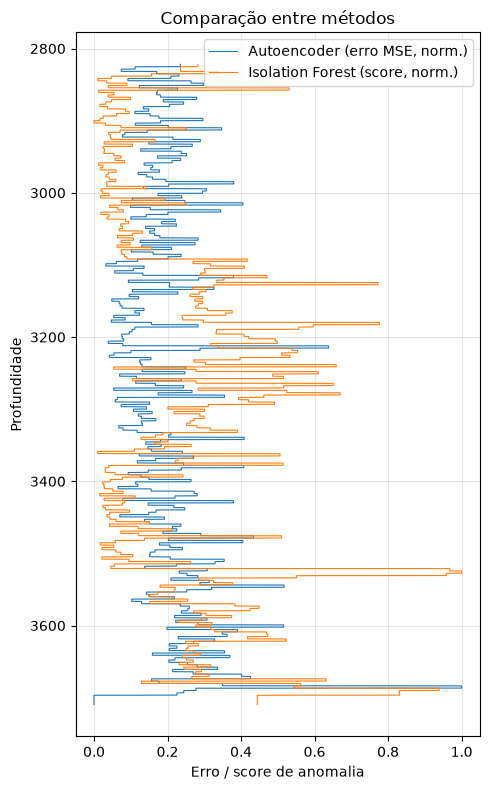

In [14]:
# Treina o Isolation Forest nas janelas de treino (embaralhadas) e avalia nas janelas ordenadas (toda a curva)
if_scores_ordered = isolation_forest_scores(train.data, windows_ordered.data, contamination=0.1)
if_scores_per_sample = np.repeat(if_scores_ordered, WINDOW_SIZE)

# normaliza os dois scores para [0, 1] só para facilitar a comparação visual (mesma escala no gráfico)
def _minmax(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

plot_method_comparison(
    full_depth,
    {
        "Autoencoder (erro MSE, norm.)": _minmax(per_sample_error),
        "Isolation Forest (score, norm.)": _minmax(if_scores_per_sample),
    },
)
plt.show()

## 8. Resumo quantitativo e discussão crítica

In [15]:
import pandas as pd

summary = pd.DataFrame([
    {"método": "Autoencoder Conv1D", "MSE": ae_scores.mse, "MAE": ae_scores.mae},
    {"método": "PCA (8 comp.)", "MSE": pca_scores.mse, "MAE": pca_scores.mae},
    {"método": "Média móvel", "MSE": ma_scores.mse, "MAE": ma_scores.mae},
])
summary

,método,MSE,MAE
0,Autoencoder Conv1D,0.001922,0.032521
1,PCA (8 comp.),0.013813,0.089128
2,Média móvel,0.011166,0.080025


**Pontos para a discussão crítica (preencher após rodar com o poço real):**

- O Autoencoder Conv1D obteve MSE/MAE menor, igual ou maior que o PCA e a média móvel? Isso é esperado dado o tamanho da base de treino (poucos poços/poucas janelas tendem a favorecer baselines lineares mais simples, como PCA).
- Os intervalos de maior erro de reconstrução (seção 6) coincidem com os intervalos apontados pelo Isolation Forest (seção 7)? Concordância entre métodos independentes aumenta a confiança de que o erro reflete um padrão real da curva, não ruído do treino.
- Este erro de reconstrução é uma indicação de comportamento **estatisticamente incomum** da curva Gamma Ray — não uma interpretação litológica ou identificação de reservatório. Qualquer leitura petrofísica desses intervalos exigiria validação por um especialista com acesso à coluna litológica e a outras curvas do poço.
- Limitações: poucas amostras (um único poço) limitam a capacidade do Autoencoder de generalizar; o `latent_channels`, `WINDOW_SIZE` e `STRIDE` foram escolhidos de forma exploratória e podem ser ajustados/justificados com uma busca de hiperparâmetros mais formal.